# IDHM por Unidade da Federação

## 1. Leitura e limpeza do CSV

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv(
    "Tabela4.csv",
    sep=";",
    decimal=",",
    encoding="cp1252",
    skiprows=1
)

df = df.dropna(axis=1, how="all")
df.columns = df.columns.str.strip()
df.head()

,Sigla,Código,Estado,1991,2000,2010,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,AC,12,Acre,0.402,0.517,0.663,0.705,0.709,0.719,0.719,0.723,0.711,0.731,0.738,0.736,0.702,0.732,0.740,0.754
1,AL,27,Alagoas,0.370,0.471,0.631,0.657,0.653,0.670,0.669,0.680,0.682,0.694,0.693,0.694,0.691,0.722,0.739,0.746
2,AM,13,Amazonas,0.430,0.515,0.674,0.706,0.717,0.720,0.724,0.723,0.743,0.732,0.739,0.725,0.700,0.757,0.764,0.767
3,AP,16,Amapá,0.472,0.577,0.708,0.709,0.735,0.726,0.728,0.732,0.731,0.737,0.732,0.707,0.681,0.743,0.767,0.759
4,BA,29,Bahia,0.386,0.512,0.660,0.684,0.686,0.700,0.708,0.708,0.715,0.714,0.723,0.726,0.698,0.734,0.740,0.759


## 2. Estados ordenados pelo maior IDH em 2024

In [2]:
ranking_2024 = df.sort_values("2024", ascending=False).reset_index(drop=True)
ranking_2024[["Sigla", "Estado", "2024"]]

,Sigla,Estado,2024
0,DF,Distrito Federal,0.866
1,SP,São Paulo,0.838
2,SC,Santa Catarina,0.833
3,PR,Paraná,0.822
4,RJ,Rio de Janeiro,0.819
5,RS,Rio Grande do Sul,0.818
6,GO,Goiás,0.815
7,MT,Mato Grosso,0.812
8,MG,Minas Gerais,0.809
9,ES,Espírito Santo,0.804


## 3. Qual estado teve a maior melhora entre 1991 e 2024?

In [3]:
evolucao = df[["Sigla", "Estado", "1991", "2024"]].copy()
evolucao["Melhora"] = (evolucao["2024"] - evolucao["1991"]).round(3)
evolucao = evolucao.sort_values("Melhora", ascending=False).reset_index(drop=True)

maior_melhora = evolucao.iloc[0]
print(
    f"{maior_melhora['Estado']} teve a maior melhora: "
    f"de {maior_melhora['1991']:.3f} para {maior_melhora['2024']:.3f}, "
    f"um aumento de {maior_melhora['Melhora']:.3f} no índice."
)
evolucao.head()

Tocantins teve a maior melhora: de 0.369 para 0.797, um aumento de 0.428 no índice.


,Sigla,Estado,1991,2024,Melhora
0,TO,Tocantins,0.369,0.797,0.428
1,PI,Piauí,0.362,0.764,0.402
2,MA,Maranhão,0.357,0.745,0.388
3,RO,Rondônia,0.407,0.786,0.379
4,PB,Paraíba,0.382,0.760,0.378


## 4. Existe alguma UF em que o IDH piorou?

Primeiro, a comparação entre 1991 e 2024. Depois, a comparação entre os dois últimos anos disponíveis.

In [4]:
pioraram = evolucao[evolucao["Melhora"] < 0]

if pioraram.empty:
    print("Nenhuma UF piorou na comparação entre 1991 e 2024.")
else:
    print(pioraram.to_string(index=False))

Nenhuma UF piorou na comparação entre 1991 e 2024.


In [5]:
pioraram_ultimo_ano = df.loc[
    df["2024"] < df["2023"],
    ["Sigla", "Estado", "2023", "2024"]
].copy()

print(f"De 2023 para 2024, {len(pioraram_ultimo_ano)} UFs tiveram queda no IDH.")
pioraram_ultimo_ano

De 2023 para 2024, 2 UFs tiveram queda no IDH.


,Sigla,Estado,2023,2024
3,AP,Amapá,0.767,0.759
6,DF,Distrito Federal,0.870,0.866


## 5. Transformação para o formato longo

In [6]:
anos = [c for c in df.columns if str(c).isdigit()]
print(anos)

id_vars = [c for c in df.columns if c not in anos]
df_longo = df.melt(
    id_vars=id_vars,
    value_vars=anos,
    var_name="Ano",
    value_name="IDH",
)
df_longo["Ano"] = df_longo["Ano"].astype(int)
df_longo["IDH"] = pd.to_numeric(df_longo["IDH"], errors="coerce")
df_longo.head()

['1991', '2000', '2010', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']


,Sigla,Código,Estado,Ano,IDH
0,AC,12,Acre,1991,0.402
1,AL,27,Alagoas,1991,0.370
2,AM,13,Amazonas,1991,0.430
3,AP,16,Amapá,1991,0.472
4,BA,29,Bahia,1991,0.386


## 6. Evolução do IDH de Minas Gerais

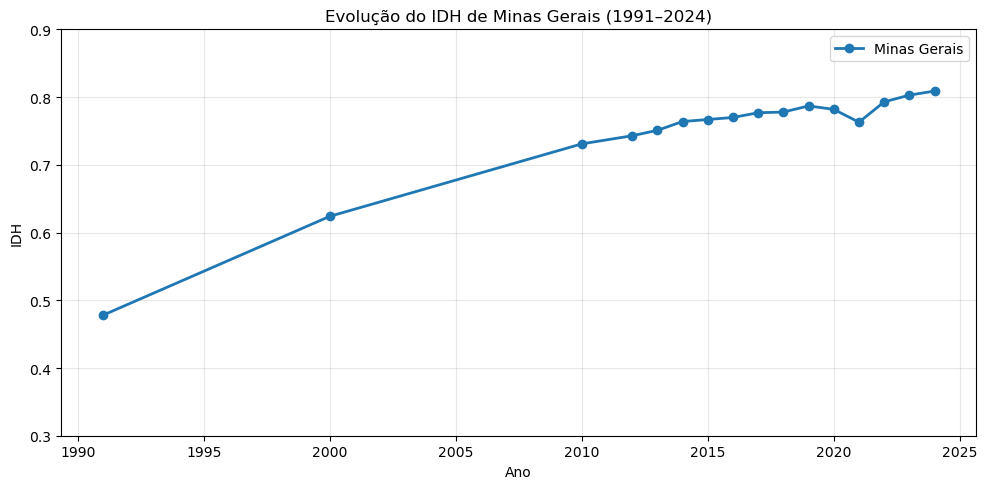

In [7]:
pasta_graficos = Path("graficos")
pasta_graficos.mkdir(exist_ok=True)

minas = df_longo[df_longo["Sigla"] == "MG"].sort_values("Ano")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(minas["Ano"], minas["IDH"], marker="o", linewidth=2, label="Minas Gerais")
ax.set_title("Evolução do IDH de Minas Gerais (1991–2024)")
ax.set_xlabel("Ano")
ax.set_ylabel("IDH")
ax.set_ylim(0.3, 0.9)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(pasta_graficos / "idh_minas_gerais.png", dpi=200)
plt.show()

## 7. Evolução do IDH de cada estado

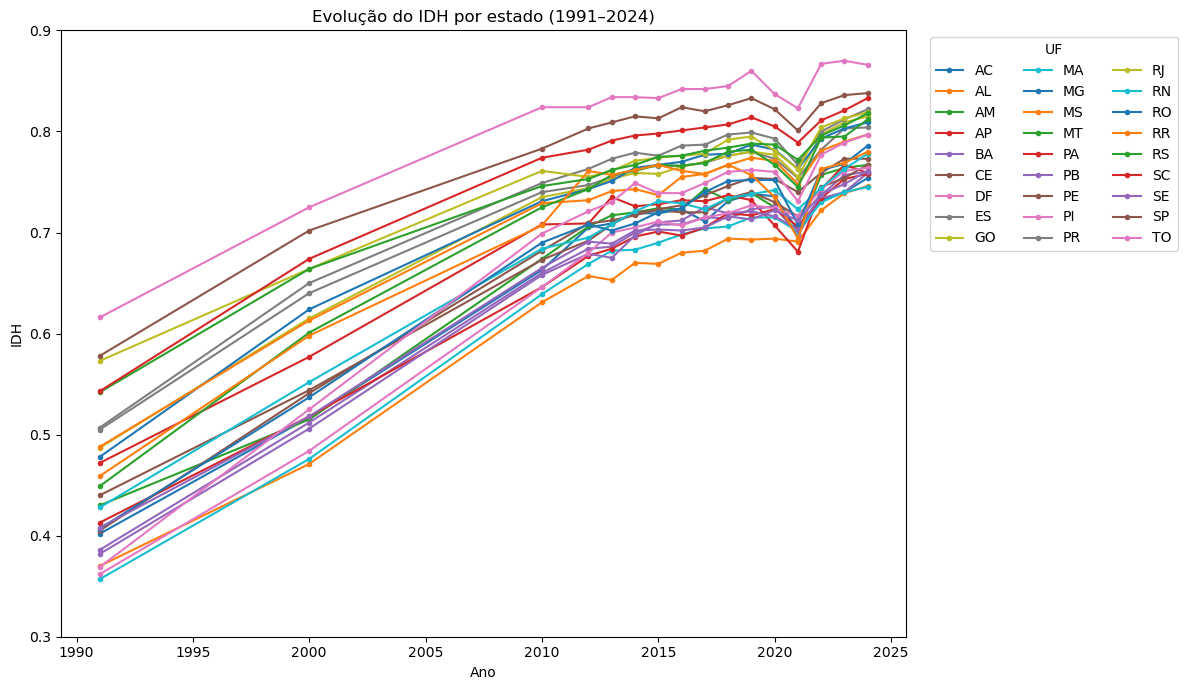

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

for sigla, grupo in df_longo.groupby("Sigla"):
    grupo = grupo.sort_values("Ano")
    ax.plot(grupo["Ano"], grupo["IDH"], marker="o", markersize=3, linewidth=1.5, label=sigla)

ax.set_title("Evolução do IDH por estado (1991–2024)")
ax.set_xlabel("Ano")
ax.set_ylabel("IDH")
ax.set_ylim(0.3, 0.9)
ax.legend(ncol=3, bbox_to_anchor=(1.02, 1), loc="upper left", title="UF")
fig.tight_layout()
fig.savefig(pasta_graficos / "idh_por_estado.png", dpi=200)
plt.show()